# 1. From a photo to 81 model inputs

This notebook follows one sudoku photo through every step that comes before the model:

1. Find the outline of the grid in the photo (`grid_detect.py`).
2. Check that the outline holds a real 9 × 9 grid (`grid_detect.py`).
3. Flatten the grid to a 576 × 576 square (`flatten.py`).
4. Cut the square into 81 cell images of 64 × 64 (`flatten.py`).
5. Turn each cell image into the 32 × 32 model input (`preprocess.py`).
6. Run the cell classifier on the 81 inputs (`model.py`).

The notebook calls the real functions of `sudoku_ml`. Where a function hides its steps, the
notebook repeats the steps with the same constants, so that you can see each picture.

**Where this code runs.** The Python code is not the scanner of the game app. The app has its own
scanner in TypeScript (`mobile/src/scanner/`). The two sides share files only (SUD-07).

| Step | Python (`ml/`) | App (`mobile/src/scanner/`) | Must they match? |
| --- | --- | --- | --- |
| Find the grid | `grid_detect.find_grid`: a proposal on the Outlines step of the labelling app | `findGrid.ts`, `chooseGrid.ts`, live on every frame | No. Two separate detectors |
| Flatten and cut | `flatten.warp_grid`, `flatten.slice_cells` | `warp.ts`, `pixels.ts` | Yes. The same numbers, so a training cell looks like an app cell |
| Preprocess | `preprocess.preprocess_cell` | `preprocess.ts` | Yes, exactly. `shared/fixtures/preprocess/` pins it |
| Classify | PyTorch `CellClassifier` | TFLite `cell-classifier.tflite` | Yes. `export.py` checks it |

```mermaid
flowchart LR
    photo["Photo<br>(H, W, 3) RGB"] --> detect["find_grid<br>4 corners"]
    detect --> warp["warp_grid<br>576 × 576"]
    warp --> slice["slice_cells<br>81 × (64, 64, 3)"]
    slice --> pre["preprocess_cell<br>81 × (32, 32)"]
    pre --> model["CellClassifier<br>digit + kind"]
```

Run the notebook from `ml/` with `just notebooks`.

## Setup

The notebook uses a **synthetic photo** by default: a rendered sudoku page, tilted and shaded on a
table. You can commit its outputs, because the image is not real data.

Set `USE_REAL_PHOTO = True` to use a photo from the image store instead.

**Clear the outputs before you commit with a real photo.** The outputs then hold pixels of a real
photo, and these must not go into git (SUD-08).

In [1]:
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFilter, ImageFont

from sudoku_ml import flatten, grid_detect, preprocess
from sudoku_ml.contract import CELL_SIZE, DIGIT_CLASSES, INPUT_SIZE, KIND_CLASSES
from sudoku_ml.data_paths import ARTIFACTS, ML_ROOT, DataPaths
from sudoku_ml.model import CellClassifier
from sudoku_ml.prelabel import default_run
from sudoku_ml.synthetic import font_files
from sudoku_ml.tables import parse_corners, read_photos

plt.rcParams["figure.dpi"] = 80
plt.rcParams["image.cmap"] = "gray"

USE_REAL_PHOTO = False
REAL_PHOTO_INDEX = 0  # the n-th photo with an accepted outline in sudoku-photos.csv


def show(*images, titles=(), size=4, cmap=None):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, image, title in zip(
        np.atleast_1d(axes), images, list(titles) + [""] * len(images), strict=False
    ):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

### A synthetic photo

`synthetic_photo` draws a page with a 9 × 9 grid and printed digits. It then warps the page onto
a table with a perspective transform, and adds light, blur and noise. The function also returns
the true corners of the grid, so that we can compare the detection with the truth.

photo (1600, 1200, 3) uint8


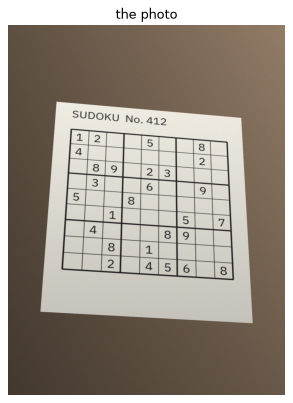

In [2]:
def synthetic_photo(seed: int = 3):
    rng = np.random.default_rng(seed)
    fonts = font_files(ML_ROOT / "fonts")
    font = ImageFont.truetype(str(fonts[0]), 44)
    grid, margin = 576, 60
    side = grid + 2 * margin
    page = Image.new("RGB", (side, side + 160), (244, 240, 230))
    draw = ImageDraw.Draw(page)
    draw.text((margin, 20), "SUDOKU  No. 412", fill=(40, 40, 40), font=font)
    top = margin + 60
    for k in range(10):
        width = 5 if k % 3 == 0 else 2
        p = k * grid / 9
        draw.line([(margin, top + p), (margin + grid, top + p)], fill=(30, 30, 30), width=width)
        draw.line([(margin + p, top), (margin + p, top + grid)], fill=(30, 30, 30), width=width)
    # A valid solution, then keep about a third of the digits as givens.
    solution = [[(r * 3 + r // 3 + c) % 9 + 1 for c in range(9)] for r in range(9)]
    for r in range(9):
        for c in range(9):
            if rng.random() < 0.35:
                x = margin + (c + 0.5) * grid / 9
                y = top + (r + 0.5) * grid / 9
                draw.text((x, y), str(solution[r][c]), fill=(25, 25, 25), font=font, anchor="mm")
    page = np.asarray(page.filter(ImageFilter.GaussianBlur(0.6)))

    height, width = 1600, 1200
    table = np.zeros((height, width, 3), np.float32)
    table[:] = np.linspace(90, 140, width)[None, :, None] * np.array([1.0, 0.85, 0.7])
    ph, pw = page.shape[:2]
    src = np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]])
    dst = np.float32([[210, 330], [1010, 400], [1060, 1290], [140, 1240]])
    h = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(page.astype(np.float32), h, (width, height))
    mask = cv2.warpPerspective(np.ones((ph, pw), np.float32), h, (width, height))[..., None]
    photo = table * (1 - mask) + warped * mask
    light = np.linspace(1.05, 0.75, height)[:, None, None]  # a shadow at the bottom
    photo = photo * light + rng.normal(0, 4, photo.shape)
    photo = np.clip(photo, 0, 255).astype(np.uint8)

    grid_src = np.float32(
        [[margin, top], [margin + grid, top], [margin + grid, top + grid], [margin, top + grid]]
    )
    true_corners = cv2.perspectiveTransform(grid_src[None], h)[0]
    return photo, true_corners


def real_photo(index: int):
    data = DataPaths.under()
    rows = [p for p in read_photos(data.photos_csv) if p.status == "accepted" and p.corners]
    row = rows[index]
    return flatten.load_upright(data.photos / row.file), np.float32(parse_corners(row.corners))


photo, true_corners = real_photo(REAL_PHOTO_INDEX) if USE_REAL_PHOTO else synthetic_photo()
print("photo", photo.shape, photo.dtype)
show(photo, titles=["the photo"], size=6)

## Step 1. Grayscale and downscale

`find_grid` works on a gray image with a long side of `DETECT_SIZE` = 800 pixels. A smaller image
makes the contour search fast. The detector multiplies the corners by `1 / scale` at the end, so
the corners are in the pixels of the full photo.

`load_upright` turns the photo by its EXIF orientation first. Every corner in the dataset is in
these upright pixels.

In [3]:
gray = cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY)
height, width = gray.shape
scale = min(1.0, grid_detect.DETECT_SIZE / max(height, width))
small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
print(f"full {gray.shape}, scale {scale:.3f}, small {small.shape}")

full (1600, 1200), scale 0.500, small (800, 600)


## Step 2. A binary image of the ink

An **adaptive threshold** compares each pixel with the Gaussian-weighted mean of its 21 × 21 neighbourhood, not with
one global value. A shadow over half the page then does not hide the lines. `THRESH_BINARY_INV`
makes ink white (255) and paper black (0), because OpenCV finds contours of white areas.

A blur before the threshold removes the paper grain. A dilation after it closes small gaps in the
grid lines, so the outer line becomes one closed contour.

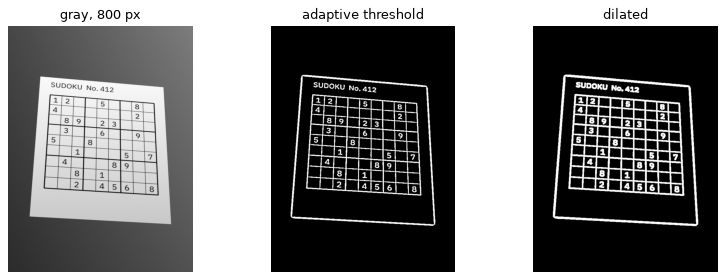

In [4]:
blur = cv2.GaussianBlur(small, (5, 5), 0)
binary = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 7
)
dilated = cv2.dilate(binary, np.ones((3, 3), np.uint8))
show(small, binary, dilated, titles=["gray, 800 px", "adaptive threshold", "dilated"])

## Step 3. Four-corner outlines

`_candidate_outlines` looks at the largest contours first:

1. The **convex hull** of a contour ignores digits and text that touch the outer grid line.
2. `approxPolyDP` simplifies the hull to a polygon. The detector tries a growing tolerance
   (`epsilon` 2 % to 6 % of the perimeter) until the polygon has 4 corners.
3. `_order` sorts the corners: top left, top right, bottom right, bottom left. The top-left
   corner has the smallest `x + y`. The top-right corner has the smallest `y - x`.
4. Two outlines that are almost the same count once. The inner and the outer edge of one thick
   line give such a pair.

The result is a short list, largest first. The page outline often comes before the grid. Step 4
decides which outline holds the grid.

6 candidates


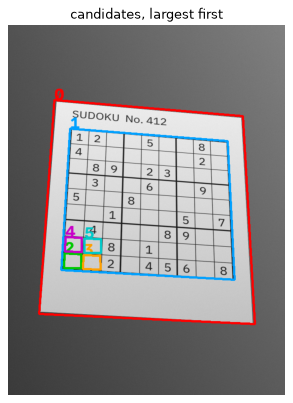

In [5]:
candidates = grid_detect._candidate_outlines(small)
print(len(candidates), "candidates")
canvas = cv2.cvtColor(small, cv2.COLOR_GRAY2RGB)
colours = [(255, 0, 0), (0, 160, 255), (0, 200, 0), (255, 160, 0), (200, 0, 200), (0, 200, 200)]
for n, quad in enumerate(candidates):
    cv2.polylines(canvas, [quad.astype(np.int32)], True, colours[n % len(colours)], 3)
    cv2.putText(
        canvas,
        str(n),
        tuple(int(v) for v in quad[0]),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.2,
        colours[n % len(colours)],
        3,
    )
show(canvas, titles=["candidates, largest first"], size=6)

## Step 4. Flatten each candidate

A **homography** is a 3 × 3 matrix that maps one quad onto another. `flatten.homography` maps the
4 corners onto a square of `FLAT_SIZE` = 9 × 64 = 576 pixels. `warp_grid` then samples the photo
for every pixel of the square, with bilinear interpolation.

The square runs from -0.5 to 575.5, not from 0 to 576. Pixel centres sit on whole numbers, so the
outer edge of the first pixel is at -0.5. The app's `warpGrid` uses the same convention. A
half-pixel error here would shift every training cell against the app cells.

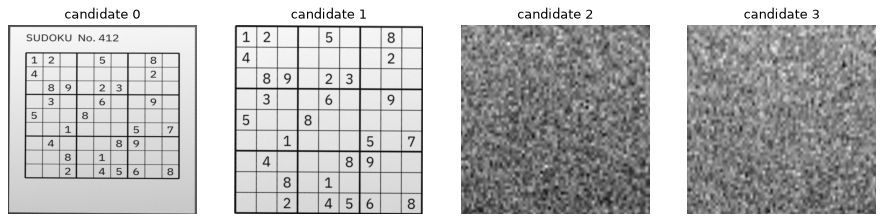

In [6]:
flats = []
for quad in candidates:
    corners = [[float(x), float(y)] for x, y in quad / scale]
    flats.append(flatten.warp_grid(gray, corners))
show(*flats[:4], titles=[f"candidate {n}" for n in range(len(flats[:4]))], size=3.5)

## Step 5. Check the grid lines

A four-corner outline is not always a grid: it can be the page, a photo frame or a box of text.
The detector checks the flattened image. In a true grid, the 10 horizontal and 10 vertical lines
sit at multiples of 64 pixels.

`_lines_in` finds them in three moves:

1. A **closing** with a 1 × 9 kernel fills small gaps in faint lines.
2. An **opening** with a 1 × 32 kernel removes every white run shorter than half a cell. Digits
   go, long lines stay. The same happens with vertical kernels for the vertical lines.
3. A **profile** gives, for each row, the share of the width that holds ink. A line is a peak.

A line **stands out** when its peak covers at least `LINE_COVERAGE` = 50 % of the width, and is
`LINE_CONTRAST` = 0.3 higher than the cell centres beside it. The search window is ±16 pixels
(`SEARCH`) around the expected position. `MIN_LINES` = 17 of 20 lines make a "full grid": a curl
or a pen mark can hide a few lines.

The detector tries two threshold offsets (`THRESHOLD_OFFSETS`). A low offset finds faint lines. A
high offset stops paper grain from looking like lines.

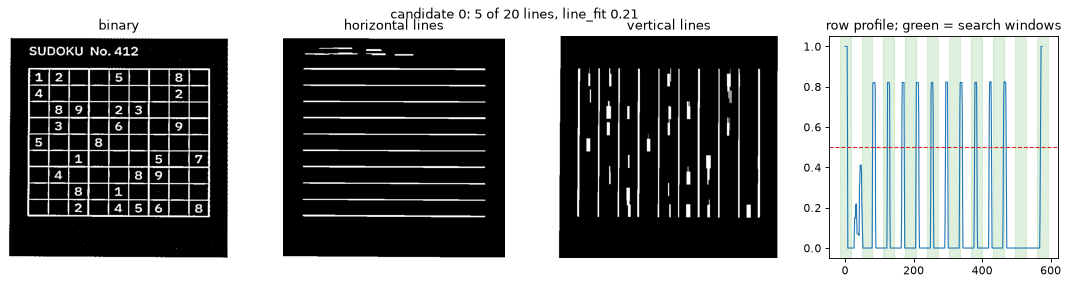

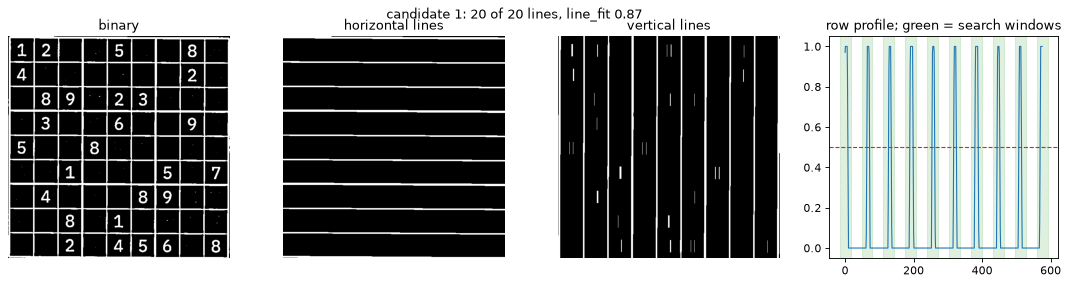

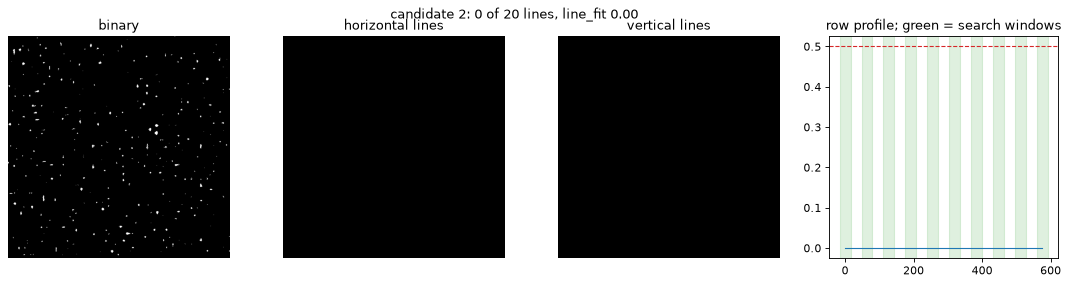

In [7]:
def line_masks(flat_gray, offset):
    blurred = cv2.GaussianBlur(flat_gray, (3, 3), 0)
    binary = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, offset
    )
    horizontal = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((1, 9), np.uint8))
    horizontal = cv2.morphologyEx(
        horizontal, cv2.MORPH_OPEN, np.ones((1, CELL_SIZE // 2), np.uint8)
    )
    vertical = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((9, 1), np.uint8))
    vertical = cv2.morphologyEx(vertical, cv2.MORPH_OPEN, np.ones((CELL_SIZE // 2, 1), np.uint8))
    return binary, horizontal, vertical


def plot_profile(flat_gray, title):
    binary, horizontal, vertical = line_masks(flat_gray, grid_detect.THRESHOLD_OFFSETS[0])
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, image, name in zip(
        axes[:3],
        (binary, horizontal, vertical),
        ("binary", "horizontal lines", "vertical lines"),
        strict=True,
    ):
        ax.imshow(image)
        ax.set_title(name)
        ax.axis("off")
    profile = grid_detect._line_profile(horizontal)
    axes[3].plot(profile, lw=1)
    for k in range(10):
        axes[3].axvspan(
            k * CELL_SIZE - grid_detect.SEARCH,
            k * CELL_SIZE + grid_detect.SEARCH,
            color="tab:green",
            alpha=0.15,
        )
    axes[3].axhline(grid_detect.LINE_COVERAGE, color="tab:red", ls="--", lw=1)
    axes[3].set_title("row profile; green = search windows")
    found = grid_detect._count_lines(flat_gray)
    fig.suptitle(f"{title}: {found} of 20 lines, line_fit {grid_detect.line_fit(flat_gray):.2f}")
    plt.show()


for n, flat_gray in enumerate(flats[:3]):
    plot_profile(flat_gray, f"candidate {n}")

## Step 6. The whole detector

`find_grid` runs steps 1 to 5. It stops at the first candidate with at least 17 lines. A candidate
whose mean edge is under 30 % of the short side of the photo ends the search
(`MIN_GRID_SHARE`): the candidates come largest first, so the rest are smaller still.

The result is a proposal. On the Outlines step of the labelling app, a person accepts it or drags
the corners. Only an accepted outline gives training cells (ADR-030).

full grid | 20 lines
largest corner error against the truth: 5.5 px


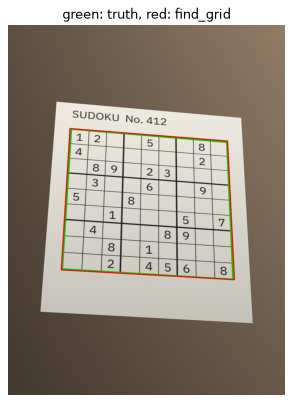

In [8]:
detection = grid_detect.find_grid(photo)
print(detection.reason, "|", detection.lines, "lines")
corners = detection.corners
error = np.abs(np.float32(corners) - true_corners).max()
print(f"largest corner error against the truth: {error:.1f} px")

canvas = photo.copy()
cv2.polylines(canvas, [true_corners.astype(np.int32)], True, (0, 200, 0), 6)
cv2.polylines(canvas, [np.int32(corners)], True, (255, 0, 0), 3)
show(canvas, titles=["green: truth, red: find_grid"], size=6)

## Step 7. 81 cell images

`slice_cells` cuts the 576 × 576 flat image into 81 squares of 64 × 64, row by row. Index
`r * 9 + c` is the cell in row `r`, column `c`. The app's `sliceCells` gives the same order.

`usable_cells` maps the 100 cell corners back into the photo. A cell with a corner outside the
photo has border pixels that `BORDER_REPLICATE` invented, so the dataset does not keep it.

**A known limit.** The flatten uses the 4 outer corners only. A curved book page bends the inner
lines, so the cells near the centre can shift. The scan pipeline concept describes a fix with 100
intersections and a flatten per cell. Neither the app nor `ml/` has it yet.

81 cells of (64, 64, 3) | 81 usable


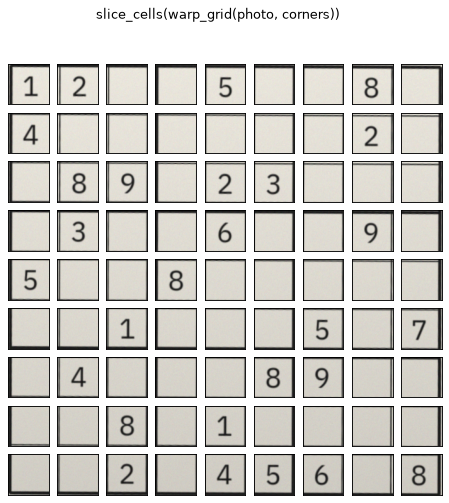

In [9]:
flat = flatten.warp_grid(photo, corners)
cell_images = flatten.slice_cells(flat)
usable = flatten.usable_cells(corners, photo.shape[1], photo.shape[0])
print(len(cell_images), "cells of", cell_images[0].shape, "|", sum(usable), "usable")

fig, axes = plt.subplots(9, 9, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(cell_images[i])
    ax.set_xticks([])
    ax.set_yticks([])
    if not usable[i]:
        ax.patch.set_edgecolor("red")
        ax.patch.set_linewidth(3)
plt.suptitle("slice_cells(warp_grid(photo, corners))")
plt.show()

## Step 8. The model input

`preprocess_cell` follows the model contract (`docs/architecture/00-concepts/model-contract.md`):

1. **Gray**: `0.299 R + 0.587 G + 0.114 B` (ITU-R BT.601).
2. **Crop**: `CROP` = (0, 64), so the model sees the whole cell (ADR-020).
3. **Resize 64 → 32** with an exact **area average**: each output pixel is the mean of a 2 × 2
   block. `area_weights` builds a matrix `W`, so the resize is `W @ image @ W.T`. A matrix product
   is easy to repeat exactly in TypeScript. `cv2.resize` has rounding details that the app cannot
   copy.
4. **Invert and scale**: `1 - gray / 255`. Ink is near 1 and paper near 0, so an empty cell is
   almost all zeros.

`preprocess_batch` does the same with PyTorch on a batch, for training on the GPU. The two must
agree.

W (32, 64) row 0 non-zero: [0.5 0.5]


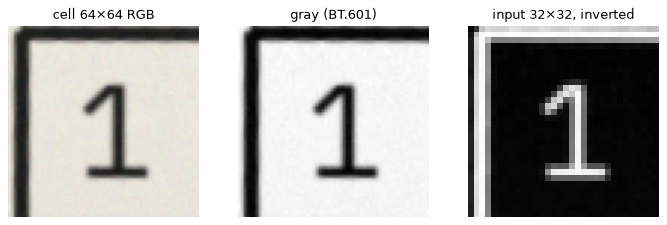

largest difference numpy vs torch: 0.0


In [10]:
cell = cell_images[next(i for i in range(81) if cell_images[i].mean() < 200)]
gray_cell = cell.astype(np.float32) @ np.float32(preprocess.BT601)
w = preprocess.area_weights(CELL_SIZE, INPUT_SIZE)
model_input = preprocess.preprocess_cell(cell)
print("W", w.shape, "row 0 non-zero:", w[0][w[0] > 0])
show(
    cell,
    gray_cell,
    model_input,
    titles=["cell 64×64 RGB", "gray (BT.601)", "input 32×32, inverted"],
    size=3.5,
)

batch = preprocess.preprocess_batch(
    torch.from_numpy(np.stack(cell_images)).permute(0, 3, 1, 2).float()
)
single = np.stack([preprocess.preprocess_cell(c) for c in cell_images])
print("largest difference numpy vs torch:", float(np.abs(batch[:, 0].numpy() - single).max()))

## Step 9. Classify the 81 cells

The model has two heads (ADR-006):

- **digit**: `empty`, `1` to `9`.
- **kind**: `none`, `printed`, `handwritten`, `notes`.

The app shows a printed digit as a given and a handwritten digit as the player's entry. The digit
head uses the **temperature** of the run (notebook 2 explains it), so its confidence is honest.

This step needs a trained run in `ml/artifacts/`. It uses the run that the app uses
(`mobile/assets/models/manifest.json`), or else the newest run.

In [11]:
try:
    run = default_run()
    if not (run / "model.pt").exists():
        raise FileNotFoundError(run)
except (OSError, KeyError):
    runs = sorted(ARTIFACTS.glob("*/model.pt"))
    run = runs[-1].parent if runs else None

if run is None:
    print("No trained run in ml/artifacts/. Run `just train` first.")
else:
    model = CellClassifier()
    model.load_state_dict(torch.load(run / "model.pt", map_location="cpu"))
    model.eval()
    temperature = json.loads((run / "metrics.json").read_text())["temperature"]
    with torch.no_grad():
        digit_logits, kind_logits = model(torch.from_numpy(single)[:, None])
    digit_p = (digit_logits / temperature).softmax(1)
    kind_p = kind_logits.softmax(1)
    print("run:", run.name, "| temperature", temperature)
    for r in range(9):
        row = []
        for c in range(9):
            d = DIGIT_CLASSES[int(digit_p[r * 9 + c].argmax())]
            row.append("." if d == "empty" else d)
        print(" ".join(row[:3]), "|", " ".join(row[3:6]), "|", " ".join(row[6:]))
    low = digit_p.max(1).values < 0.9
    print("cells under 90 % confidence:", low.nonzero().ravel().tolist())
    kinds = [KIND_CLASSES[int(k)] for k in kind_p.argmax(1)]
    print("kinds:", {k: kinds.count(k) for k in KIND_CLASSES})

run: 20261013-140341-cell-classifier | temperature 0.602
1 2 . | . 5 . | . 8 .
4 . . | . . . | . 2 .
. 8 9 | . 2 3 | . . .
. 3 . | . 6 . | . 9 .
5 . . | 8 . . | . . .
. . 1 | . . . | 5 . 7
. 4 . | . . 8 | 9 . .
. . 8 | . 1 . | . . .
. . 2 | . 4 5 | 6 . 8
cells under 90 % confidence: []
kinds: {'none': 53, 'printed': 28, 'handwritten': 0, 'notes': 0}


## Summary

| Step | Function | Shape after the step |
| --- | --- | --- |
| Photo | `load_upright` | (H, W, 3) uint8 |
| Outline | `find_grid` | 4 corners in photo pixels |
| Flatten | `warp_grid` | (576, 576, 3) uint8 |
| Cut | `slice_cells` | 81 × (64, 64, 3) uint8 |
| Preprocess | `preprocess_cell` | 81 × (32, 32) float32, 0 = paper, 1 = ink |
| Classify | `CellClassifier` | digit (81, 10), kind (81, 4) |

Notebook 2 shows where the training cells come from and how the model learns from them.